# Notebook 03 — Componente supervisado: predecir si la sesión termina en compra

**Problema:** clasificación binaria con **desbalance** (~15,6 % de compras). **Objetivo:** estimar la probabilidad de compra de una sesión y decidir cuándo intervenir.

**Diseño experimental (sin fuga de información):**
1. División estratificada 80/20 fijada en `src/preprocesamiento.py`; **el test no se toca hasta el final**.
2. Todo el preprocesamiento va **dentro de un `Pipeline`**, así en cada pliegue de validación cruzada el escalado y la codificación se ajustan solo con los datos de entrenamiento de ese pliegue.
3. Los modelos se **comparan con validación cruzada estratificada de 5 pliegues sobre train**; la selección de hiperparámetros y del **umbral de decisión** también se hace solo con train.
4. El test se usa **una sola vez**, para reportar el desempeño final del modelo elegido.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sys.path.insert(0, str(RAIZ / 'src'))
from preprocesamiento import (cargar_datos, dividir_train_test, construir_preprocesador, matriz_conducta,
                              NUMERICAS, CATEGORICAS, BINARIAS, CONDUCTA, OBJETIVO, SEMILLA, MESES_ORDEN)

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix)

df = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(df)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f'train: {len(X_train):,} sesiones ({y_train.mean():.1%} compra) | test: {len(X_test):,} ({y_test.mean():.1%} compra)')

def hacer_pipeline(modelo, page_values=True):
    """Preprocesador + modelo en un solo objeto: el preprocesador se ajusta dentro de cada pliegue."""
    return Pipeline([('prep', construir_preprocesador(incluir_page_values=page_values)), ('modelo', modelo)])

METRICAS = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}

def evaluar_cv(nombre, modelo, page_values=True):
    """Validacion cruzada estratificada sobre TRAIN. Devuelve media y desviacion de cada metrica."""
    r = cross_validate(hacer_pipeline(modelo, page_values), X_train, y_train, cv=CV, scoring=METRICAS, n_jobs=-1)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = r[f'test_{m}'].mean()
        fila[m + '_std'] = r[f'test_{m}'].std()
    return fila

resultados_cv = []     # aqui se acumulan los resultados de cada modelo

train: 9,764 sesiones (15.6% compra) | test: 2,441 (15.6% compra)


## 1. Algoritmos seleccionados y por qué

| Modelo | Por qué es apropiado aquí | Supuestos principales | Ventajas | Limitaciones |
|---|---|---|---|---|
| **Regresión logística** | Línea base interpretable: cada coeficiente dice cómo cambia la probabilidad de compra | Relación **lineal** entre las variables (transformadas) y el log-odds; observaciones independientes; poca multicolinealidad | Rápida, interpretable, probabilidades bien calibradas | No captura interacciones ni relaciones no lineales; sensible a `BounceRates`/`ExitRates` correlacionadas |
| **Random Forest** | Captura **no linealidades e interacciones** (p. ej. `PageValues` × tipo de visitante) y es robusto a atípicos | Casi ninguno (no requiere escalado ni linealidad) | Robusto, poco sobreajuste, da importancia de variables | Menos interpretable; probabilidades menos calibradas; más lento |
| **Gradient Boosting (HistGradientBoosting)** | Suele ser el mejor en datos tabulares; construye árboles en secuencia corrigiendo errores | Casi ninguno; requiere ajustar tasa de aprendizaje y profundidad | Muy preciso, rápido, maneja desbalance con pesos | Puede sobreajustar si no se regulariza; es una "caja negra" |

La comparación de **tres** modelos (mínimo exigido: dos) permite ver cuánto aporta pasar de un modelo lineal a modelos de árboles.

## 2. Métricas: por qué no basta el accuracy

Con 84,4 % de sesiones sin compra, un modelo que **siempre responde "no compra" tiene 84,4 % de accuracy y no detecta ninguna compra**. Por eso se usan:

| Métrica | Qué responde | Por qué importa aquí |
|---|---|---|
| **Recall** | De las sesiones que sí compran, ¿cuántas detectamos? | Una compra no detectada es una oportunidad perdida |
| **Precision** | De las que marcamos como "compra", ¿cuántas compran de verdad? | Intervenir (ofrecer cupón) tiene costo |
| **F1** | Equilibrio entre precision y recall | Resume ambos en un número |
| **ROC-AUC** | Capacidad de ordenar compras por encima de no-compras | Independiente del umbral |
| **PR-AUC** | Igual, pero sensible al desbalance | **Métrica principal** para comparar: es más exigente que ROC-AUC cuando la clase positiva es rara |

## 3. Línea base: ¿qué tan bueno es "no hacer nada inteligente"?

In [3]:
base_mayor = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred = base_mayor.predict(X_test)
print('Linea base "siempre NO compra" (evaluada en test solo para ilustrar la trampa del accuracy):')
print(f'  accuracy = {accuracy_score(y_test, pred):.3f} | recall = {recall_score(y_test, pred):.3f} | F1 = {f1_score(y_test, pred):.3f}')

azar = DummyClassifier(strategy='prior').fit(X_train, y_train)
print(f'  PR-AUC de un modelo sin informacion = tasa de compra = {y_test.mean():.3f}  (el "piso" para la PR-AUC)')

Linea base "siempre NO compra" (evaluada en test solo para ilustrar la trampa del accuracy):
  accuracy = 0.844 | recall = 0.000 | F1 = 0.000
  PR-AUC de un modelo sin informacion = tasa de compra = 0.156  (el "piso" para la PR-AUC)


## 4. Regresión logística y la estrategia para el desbalance
Se compara la regresión logística **sin** y **con** `class_weight='balanced'` (que pondera más a la clase rara) para justificar con datos la estrategia contra el desbalance.

In [4]:
lr_sin = LogisticRegression(max_iter=2000)
lr_bal = LogisticRegression(max_iter=2000, class_weight='balanced')
comparacion_peso = pd.DataFrame([evaluar_cv('LR sin class_weight', lr_sin), evaluar_cv('LR con class_weight balanced', lr_bal)])
comparacion_peso[['modelo', 'roc_auc', 'pr_auc', 'f1', 'recall', 'precision']]

,modelo,roc_auc,pr_auc,f1,recall,precision
0,LR sin class_weight,0.912,0.683,0.616,0.548,0.705
1,LR con class_weight balanced,0.916,0.664,0.647,0.796,0.546


**¿Sirve `class_weight='balanced'`?**
- Sin pesos, la regresión logística es **conservadora**: precisión 0,705 pero **recall solo 0,548** (se le escapan casi la mitad de las compras). Con pesos, **el recall sube a 0,796** a costa de la precisión (0,546); el F1 mejora de 0,616 a 0,647 con el umbral por defecto.
- Los pesos **no mejoran la capacidad de ordenar** (PR-AUC 0,664 con pesos frente a 0,683 sin pesos; ROC-AUC 0,916 vs 0,912): lo que cambian es **dónde queda el punto de operación**. Por eso, más adelante el umbral se ajusta de forma explícita en lugar de depender solo de los pesos.
- Se conservan los pesos en los tres modelos para que las comparaciones sean homogéneas.

In [5]:
resultados_cv.append(evaluar_cv('Regresion logistica', lr_bal))
pd.DataFrame(resultados_cv)[['modelo', 'roc_auc', 'pr_auc', 'f1', 'recall', 'precision']]

,modelo,roc_auc,pr_auc,f1,recall,precision
0,Regresion logistica,0.916,0.664,0.647,0.796,0.546


## 5. Random Forest y Gradient Boosting
Se entrenan con los mismos pliegues de validación cruzada, de modo que la comparación es justa.

In [6]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample',
                            random_state=SEMILLA, n_jobs=-1)
hgb = HistGradientBoostingClassifier(class_weight='balanced', random_state=SEMILLA)

resultados_cv.append(evaluar_cv('Random Forest', rf))
resultados_cv.append(evaluar_cv('Gradient Boosting', hgb))
cv_tabla = pd.DataFrame(resultados_cv).set_index('modelo')
cv_tabla[['roc_auc', 'pr_auc', 'f1', 'recall', 'precision']]

,roc_auc,pr_auc,f1,recall,precision
modelo,,,,,
Regresion logistica,0.916,0.664,0.647,0.796,0.546
Random Forest,0.928,0.737,0.686,0.740,0.641
Gradient Boosting,0.926,0.740,0.669,0.782,0.585


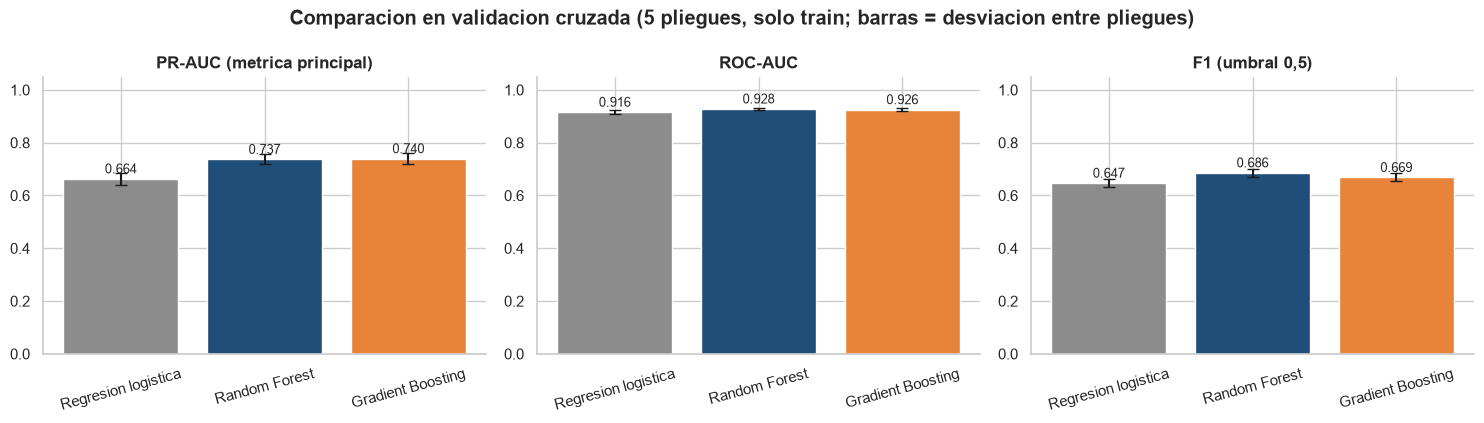

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
colores = [GRIS, AZUL, NARANJA]
for ax, m, tit in zip(axs, ['pr_auc', 'roc_auc', 'f1'], ['PR-AUC (metrica principal)', 'ROC-AUC', 'F1 (umbral 0,5)']):
    ax.bar(cv_tabla.index, cv_tabla[m], yerr=cv_tabla[m + '_std'], color=colores, capsize=4)
    for i, v in enumerate(cv_tabla[m]):
        ax.text(i, v + .02, f'{v:.3f}', ha='center', fontsize=9)
    ax.set_title(tit); ax.set_ylim(0, 1.05); ax.tick_params(axis='x', rotation=15)
plt.suptitle('Comparacion en validacion cruzada (5 pliegues, solo train; barras = desviacion entre pliegues)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / '03_comparacion_cv.png', dpi=150, bbox_inches='tight')
plt.show()

**Comparación en validación cruzada (solo train)**

| Modelo | PR-AUC | ROC-AUC | F1 (umbral 0,5) | Recall | Precision |
|---|---|---|---|---|---|
| Regresión logística | 0,664 | 0,916 | 0,647 | 0,796 | 0,546 |
| Random Forest | 0,737 | 0,928 | 0,686 | 0,740 | 0,641 |
| Gradient Boosting | 0,740 | 0,926 | 0,669 | 0,782 | 0,585 |

- Los **modelos de árboles superan claramente a la regresión logística en PR-AUC (+0,07)**: hay **no linealidades e interacciones** que el modelo lineal no captura.
- **Random Forest y Gradient Boosting están empatados** (diferencia de 0,003 en PR-AUC, muy inferior a la desviación entre pliegues, ≈ 0,02): no se puede declarar un ganador solo con estos datos. El ajuste de hiperparámetros y el criterio fuera de muestra (siguiente sección) deciden.
- En ROC-AUC las tres diferencias parecen pequeñas (0,916–0,928): **la ROC-AUC es optimista con clases desbalanceadas**, la PR-AUC separa mejor a los modelos.

## 6. Ajuste de hiperparámetros

Se ajustan **Random Forest** y **Gradient Boosting** con búsqueda aleatoria (`RandomizedSearchCV`) optimizando **PR-AUC**, usando solo train y los mismos pliegues. La regresión logística se deja con sus valores por defecto (casi no tiene hiperparámetros relevantes).

In [8]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV

espacios = {
    'Random Forest': (RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=SEMILLA, n_jobs=-1),
                      {'modelo__max_depth': [6, 8, 12, 16, None], 'modelo__min_samples_leaf': randint(2, 20),
                       'modelo__max_features': ['sqrt', 0.3, 0.5]}, 12),
    'Gradient Boosting': (HistGradientBoostingClassifier(class_weight='balanced', random_state=SEMILLA),
                          {'modelo__learning_rate': loguniform(0.01, 0.2), 'modelo__max_leaf_nodes': randint(8, 48),
                           'modelo__min_samples_leaf': randint(10, 80), 'modelo__l2_regularization': loguniform(1e-3, 10),
                           'modelo__max_iter': [100, 200, 300]}, 15),
}
mejores = {}
for nombre, (modelo, grid, n_iter) in espacios.items():
    busqueda = RandomizedSearchCV(hacer_pipeline(modelo), grid, n_iter=n_iter, scoring='average_precision',
                                  cv=CV, random_state=SEMILLA, n_jobs=-1)
    busqueda.fit(X_train, y_train)
    mejores[nombre] = busqueda.best_estimator_
    print(f'{nombre}: PR-AUC en CV = {busqueda.best_score_:.3f}  |  mejores parametros: ',
          {k.replace("modelo__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in busqueda.best_params_.items()})

Random Forest: PR-AUC en CV = 0.754  |  mejores parametros:  {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 12}


Gradient Boosting: PR-AUC en CV = 0.751  |  mejores parametros:  {'l2_regularization': np.float64(0.1538), 'learning_rate': np.float64(0.0174), 'max_iter': 300, 'max_leaf_nodes': 25, 'min_samples_leaf': 53}


## 7. Umbral de decisión (elegido solo con train)

Un modelo devuelve una **probabilidad**; hay que decidir a partir de qué probabilidad se marca la sesión como "compra". El umbral por defecto (0,5) no es óptimo con clases desbalanceadas. Se obtienen **predicciones fuera de muestra** (`cross_val_predict`) sobre train y se elige el umbral que maximiza el **F1**. Así **el test no interviene en la elección**.

In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, roc_curve

candidatos = {'Regresion logistica': hacer_pipeline(lr_bal), 'Random Forest': mejores['Random Forest'],
              'Gradient Boosting': mejores['Gradient Boosting']}
oof, umbrales = {}, {}
for nombre, pipe in candidatos.items():
    oof[nombre] = cross_val_predict(pipe, X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(y_train, oof[nombre])
    f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    umbrales[nombre] = float(t[np.argmax(f1s)])
    print(f'{nombre:<22} umbral que maximiza F1 en train (fuera de muestra): {umbrales[nombre]:.3f}  (F1 = {f1s.max():.3f})')

# El modelo se ELIGE con la PR-AUC fuera de muestra sobre TRAIN (nunca con el test)
pr_oof = {n: average_precision_score(y_train, o) for n, o in oof.items()}
mejor = max(pr_oof, key=pr_oof.get)
print('PR-AUC fuera de muestra en train:', {n: round(v, 3) for n, v in pr_oof.items()}, '->  modelo elegido:', mejor)

Regresion logistica    umbral que maximiza F1 en train (fuera de muestra): 0.608  (F1 = 0.665)


Random Forest          umbral que maximiza F1 en train (fuera de muestra): 0.673  (F1 = 0.694)


Gradient Boosting      umbral que maximiza F1 en train (fuera de muestra): 0.703  (F1 = 0.691)
PR-AUC fuera de muestra en train: {'Regresion logistica': 0.662, 'Random Forest': 0.752, 'Gradient Boosting': 0.749} ->  modelo elegido: Random Forest


## 8. Evaluación final en el conjunto de prueba (se usa una sola vez)

In [10]:
finales, probas_test = [], {}
for nombre, pipe in candidatos.items():
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    probas_test[nombre] = prob
    pred = (prob >= umbrales[nombre]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    finales.append({'modelo': nombre, 'umbral': umbrales[nombre], 'precision': precision_score(y_test, pred),
                    'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred),
                    'roc_auc': roc_auc_score(y_test, prob), 'pr_auc': average_precision_score(y_test, prob),
                    'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn})
tabla_final = pd.DataFrame(finales).set_index('modelo')
tabla_final

,umbral,precision,recall,f1,roc_auc,pr_auc,VP,FP,FN,VN
modelo,,,,,,,,,,
Regresion logistica,0.608,0.602,0.764,0.674,0.926,0.678,292,193,90,1866
Random Forest,0.673,0.653,0.728,0.688,0.936,0.751,278,148,104,1911
Gradient Boosting,0.703,0.643,0.736,0.686,0.934,0.754,281,156,101,1903


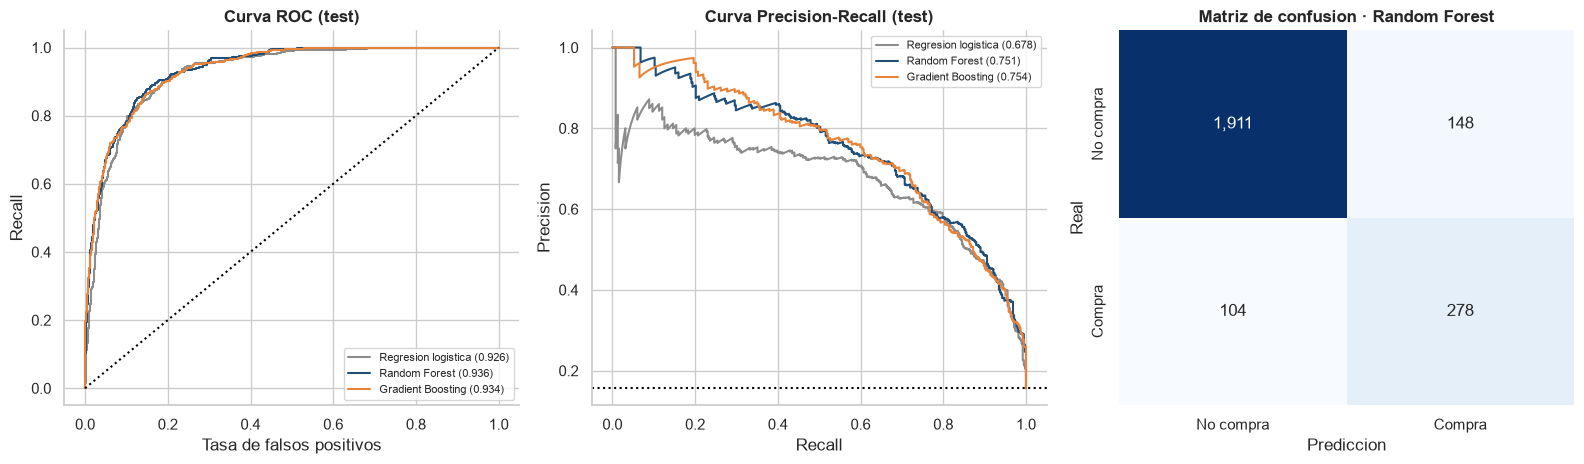

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
colores = {'Regresion logistica': GRIS, 'Random Forest': AZUL, 'Gradient Boosting': NARANJA}
for nombre, prob in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, prob); axs[0].plot(fpr, tpr, color=colores[nombre], label=f'{nombre} ({roc_auc_score(y_test, prob):.3f})')
    p, r, _ = precision_recall_curve(y_test, prob); axs[1].plot(r, p, color=colores[nombre], label=f'{nombre} ({average_precision_score(y_test, prob):.3f})')
axs[0].plot([0, 1], [0, 1], ':', color='black'); axs[0].set_title('Curva ROC (test)'); axs[0].set_xlabel('Tasa de falsos positivos'); axs[0].set_ylabel('Recall'); axs[0].legend(fontsize=8)
axs[1].axhline(y_test.mean(), ls=':', color='black'); axs[1].set_title('Curva Precision-Recall (test)'); axs[1].set_xlabel('Recall'); axs[1].set_ylabel('Precision'); axs[1].legend(fontsize=8)

pred = (probas_test[mejor] >= umbrales[mejor]).astype(int)
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axs[2], xticklabels=['No compra', 'Compra'], yticklabels=['No compra', 'Compra'])
axs[2].set_title(f'Matriz de confusion · {mejor}'); axs[2].set_xlabel('Prediccion'); axs[2].set_ylabel('Real')
plt.tight_layout()
plt.savefig(FIG / '03_evaluacion_test.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Se guardan los resultados para el notebook 05 y la documentacion
import json
tabla_final.round(4).to_csv(RES / 'metricas_supervisado_test.csv')
pd.DataFrame(resultados_cv).round(4).to_csv(RES / 'metricas_supervisado_cv.csv', index=False)
params = {k: v for k, v in candidatos[mejor].named_steps['modelo'].get_params().items()
          if isinstance(v, (int, float, str, bool, type(None)))}     # solo valores simples, para poder reconstruir el modelo
json.dump({'mejor_modelo': mejor, 'umbral': umbrales[mejor], 'params': params, 'umbrales': umbrales},
          open(RES / 'modelo_final.json', 'w'), indent=2)
print('Modelo elegido (mayor PR-AUC fuera de muestra en train):', mejor, '| guardado en resultados/')

Modelo elegido (mayor PR-AUC fuera de muestra en train): Random Forest | guardado en resultados/


**Resultados finales en test** (el umbral y el modelo se eligieron solo con train)

| Modelo | Umbral | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Regresión logística | 0,608 | 0,602 | 0,764 | 0,674 | 0,926 | 0,678 |
| **Random Forest (elegido)** | **0,673** | **0,653** | **0,728** | **0,688** | **0,936** | **0,751** |
| Gradient Boosting | 0,703 | 0,643 | 0,736 | 0,686 | 0,934 | 0,754 |

- **Elección:** el modelo se escogió por la **PR-AUC fuera de muestra en train** (RF 0,752 · GB 0,749 · LR 0,662), **no por el test**. Es un empate técnico entre RF y GB; en test las diferencias (0,003 en PR-AUC) no son significativas con 382 compras.
- **El modelo elegido detecta 278 de las 382 compras (recall 72,8 %)**; de las 426 sesiones que marca como "compra", 278 compran de verdad (precision 65,3 %): cuatro veces la tasa base de 15,6 %. Deja pasar 104 compras (falsos negativos) y marca 148 sesiones que no compran (falsos positivos).
- Un intervalo de confianza aproximado del 95 % del recall es ±4,5 puntos (72,8 % ± 4,5), así que **el modelo lineal (76,4 %) y los de árboles (72,8–73,6 %) son equivalentes en recall**; donde los de árboles ganan es en **precision y en PR-AUC**.
- **Comparación con la línea base:** un modelo sin información tendría PR-AUC = 0,156; el elegido logra 0,751 (**4,8 veces** más) y ROC-AUC de 0,936.
- Generalización: el desempeño en test (PR-AUC 0,751) es consistente con el de validación cruzada (0,752 fuera de muestra); **no hay sobreajuste evidente**.

## 9. ¿Qué variables importan? Importancia por permutación

Se mezcla al azar una variable del **test** y se mide cuánto cae la **PR-AUC**: si cae mucho, el modelo dependía de ella. Se hace sobre las columnas originales (el pipeline hace el preprocesamiento), así cada barra es una variable que el negocio reconoce.

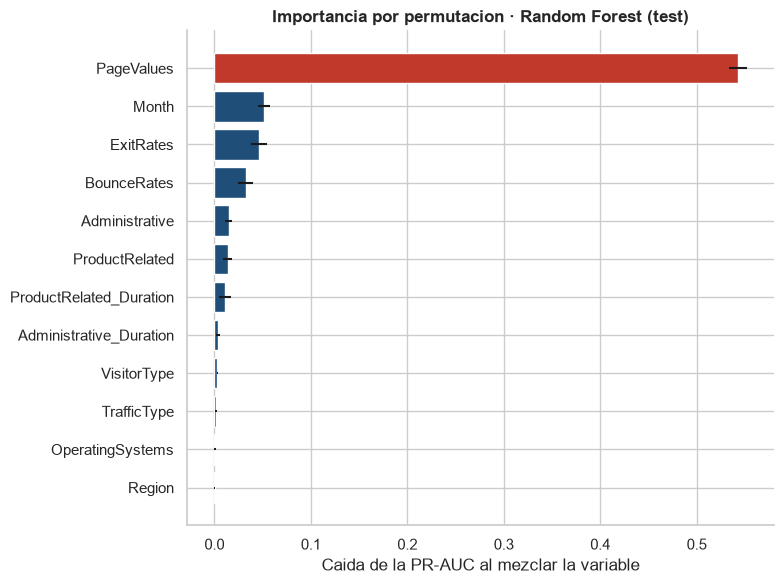

,caida PR-AUC,std
PageValues,0.543,0.009
Month,0.051,0.006
ExitRates,0.046,0.008
BounceRates,0.033,0.008
Administrative,0.015,0.004
ProductRelated,0.014,0.004
ProductRelated_Duration,0.011,0.006
Administrative_Duration,0.004,0.002


In [13]:
from sklearn.inspection import permutation_importance

modelo_final = candidatos[mejor]
perm = permutation_importance(modelo_final, X_test, y_test, scoring='average_precision', n_repeats=15,
                              random_state=SEMILLA, n_jobs=-1)
imp = pd.DataFrame({'caida PR-AUC': perm.importances_mean, 'std': perm.importances_std}, index=X_test.columns)
imp = imp.sort_values('caida PR-AUC', ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top = imp.head(12)[::-1]
ax.barh(top.index, top['caida PR-AUC'], xerr=top['std'], color=[ROJO if c == 'PageValues' else AZUL for c in top.index])
ax.set_title(f'Importancia por permutacion · {mejor} (test)'); ax.set_xlabel('Caida de la PR-AUC al mezclar la variable')
plt.tight_layout()
plt.savefig(FIG / '03_importancia_permutacion.png', dpi=150, bbox_inches='tight')
plt.show()
imp.head(8).round(4)

**Qué variables mueven la predicción**
- **`PageValues` es abrumadora:** al mezclarla, la PR-AUC cae **0,54** (de 0,75). La siguiente, `Month`, solo 0,05.
- Después vienen `ExitRates` (0,046), `BounceRates` (0,033), `Administrative` (0,015), `ProductRelated` (0,014) y `ProductRelated_Duration` (0,011): **cuanto más se navega y menos rebota o sale, más probable es la compra**, coherente con el EDA.
- `Month` pesa por la estacionalidad (octubre–noviembre compran más).
- Variables como `Browser`, `Region` o `Weekend` casi no aportan.
- **La importancia por permutación subestima el peso de variables correlacionadas** (conteos y duraciones se reparten el crédito), así que cada una se ve pequeña aunque juntas sean relevantes.

## 10. Ablación de `PageValues`: ¿cuánto depende el modelo de una sola variable?

`PageValues` se calcula con información del resultado (ver notebook 01). Para medir el riesgo de fuga se **reentrenan los mismos modelos sin esa variable** y se comparan los resultados en validación cruzada y test.

In [14]:
from sklearn.base import clone

sin_pv = []
for nombre, base in [('Regresion logistica', lr_bal), ('Random Forest', mejores['Random Forest'].named_steps['modelo']),
                     ('Gradient Boosting', mejores['Gradient Boosting'].named_steps['modelo'])]:
    fila = evaluar_cv(nombre, base, page_values=False)
    pipe = hacer_pipeline(clone(base), page_values=False).fit(X_train, y_train)   # clone: no tocar los modelos ya entrenados
    prob = pipe.predict_proba(X_test)[:, 1]
    con = tabla_final.loc[nombre]
    sin_pv.append({'modelo': nombre, 'PR-AUC CV con PV': cv_tabla.loc[nombre, 'pr_auc'], 'PR-AUC CV sin PV': fila['pr_auc'],
                   'PR-AUC test con PV': con['pr_auc'], 'PR-AUC test sin PV': average_precision_score(y_test, prob),
                   'ROC-AUC test con PV': con['roc_auc'], 'ROC-AUC test sin PV': roc_auc_score(y_test, prob)})
ablacion = pd.DataFrame(sin_pv).set_index('modelo')
ablacion

,PR-AUC CV con PV,PR-AUC CV sin PV,PR-AUC test con PV,PR-AUC test sin PV,ROC-AUC test con PV,ROC-AUC test sin PV
modelo,,,,,,
Regresion logistica,0.664,0.331,0.678,0.336,0.926,0.761
Random Forest,0.737,0.377,0.751,0.373,0.936,0.785
Gradient Boosting,0.740,0.385,0.754,0.380,0.934,0.794


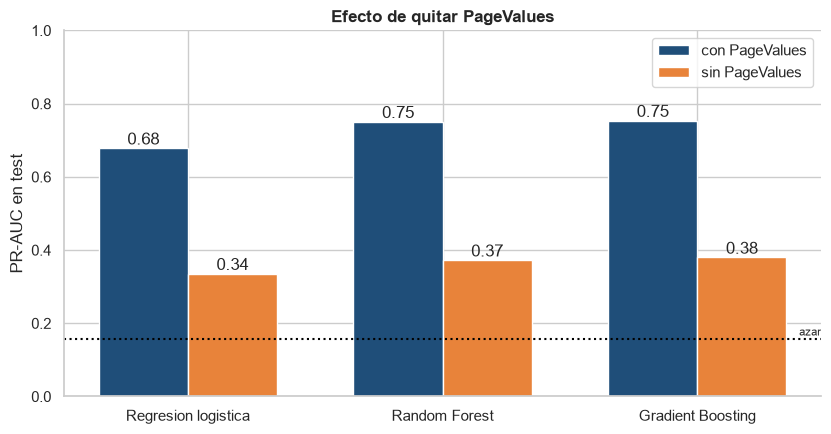

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x = np.arange(len(ablacion)); w = .35
ax.bar(x - w / 2, ablacion['PR-AUC test con PV'], w, color=AZUL, label='con PageValues')
ax.bar(x + w / 2, ablacion['PR-AUC test sin PV'], w, color=NARANJA, label='sin PageValues')
for i, (a, b) in enumerate(zip(ablacion['PR-AUC test con PV'], ablacion['PR-AUC test sin PV'])):
    ax.text(i - w / 2, a + .01, f'{a:.2f}', ha='center'); ax.text(i + w / 2, b + .01, f'{b:.2f}', ha='center')
ax.axhline(y_test.mean(), ls=':', color='black'); ax.text(2.4, y_test.mean() + .01, 'azar', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ablacion.index); ax.set_ylabel('PR-AUC en test'); ax.set_ylim(0, 1)
ax.set_title('Efecto de quitar PageValues'); ax.legend()
plt.tight_layout()
plt.savefig(FIG / '03_ablacion_pagevalues.png', dpi=150, bbox_inches='tight')
plt.show()

**Esta es la conclusión más importante del componente supervisado.**

| PR-AUC en test | Con `PageValues` | Sin `PageValues` | Azar |
|---|---|---|---|
| Regresión logística | 0,678 | **0,336** | 0,156 |
| Random Forest | 0,751 | **0,373** | 0,156 |
| Gradient Boosting | 0,754 | **0,380** | 0,156 |

(ROC-AUC en test: de 0,926–0,936 a 0,761–0,794.)

- **Sin `PageValues`, la PR-AUC cae a la mitad.** Más de la mitad del desempeño depende de una sola variable.
- Sin ella los modelos **siguen siendo mejores que el azar** (PR-AUC 0,37 frente a 0,156: **2,4 veces** más), es decir, el comportamiento de navegación sí contiene señal real, pero es **mucho más débil**.
- Esto **no demuestra por sí solo que haya fuga**; depende de **cuándo se calcula** `PageValues` en un sistema real. Si el valor se conoce *antes* del pago (p. ej. el valor promedio histórico de las páginas visitadas), es una variable legítima; si se actualiza con la transacción de la propia sesión, es fuga y el modelo no serviría para intervenir a tiempo.
- **Conclusión práctica:** el modelo "completo" (F1 ≈ 0,69) describe lo que ocurre *con* ese dato; el realista para actuar mientras el visitante navega es el modelo *sin* `PageValues` (rendimiento mucho más modesto). La recomendación final (notebook 05) lo tiene en cuenta.

## 11. Análisis de errores
¿A quiénes se les escapa la compra (falsos negativos) y a quiénes se les "ofrece" sin comprar (falsos positivos)?

In [16]:
pred = (probas_test[mejor] >= umbrales[mejor]).astype(int)
err = X_test.copy()
err['real'] = y_test.values; err['pred'] = pred
err['grupo'] = np.select([(err.real == 1) & (err.pred == 1), (err.real == 1) & (err.pred == 0), (err.real == 0) & (err.pred == 1)],
                         ['Verdadero positivo', 'Falso negativo', 'Falso positivo'], 'Verdadero negativo')
perfil = err.groupby('grupo').agg(sesiones=('grupo', 'size'), PageValues=('PageValues', 'mean'), ProductRelated=('ProductRelated', 'mean'),
                                  ExitRates=('ExitRates', 'mean'), BounceRates=('BounceRates', 'mean'),
                                  nuevos=('VisitorType', lambda s: (s == 'New_Visitor').mean()))
perfil

,sesiones,PageValues,ProductRelated,ExitRates,BounceRates,nuevos
grupo,,,,,,
Falso negativo,104,2.468,54.346,0.029,0.010,0.221
Falso positivo,148,23.149,53.196,0.021,0.006,0.047
Verdadero negativo,1911,0.433,26.305,0.047,0.025,0.126
Verdadero positivo,278,36.158,49.935,0.016,0.003,0.266


**Perfil de los errores del Random Forest elegido**

| Grupo | Sesiones | `PageValues` medio | Páginas de producto | `ExitRates` | % visitantes nuevos |
|---|---|---|---|---|---|
| Verdadero positivo | 278 | 36,2 | 49,9 | 0,016 | 26,6 % |
| **Falso negativo** (compra no detectada) | 104 | **2,5** | **54,3** | 0,029 | 22,1 % |
| **Falso positivo** (alarma sin compra) | 148 | **23,1** | 53,2 | 0,021 | 4,7 % |
| Verdadero negativo | 1.911 | 0,4 | 26,3 | 0,047 | 12,6 % |

- Los **falsos negativos son compradores muy activos (54 páginas de producto) pero con `PageValues` casi nulo**: compran sin pasar por las páginas de "alto valor", y el modelo, que se apoya en `PageValues`, los pierde.
- Los **falsos positivos tienen `PageValues` alto (23) pero no compran**: visitantes que recorren páginas valiosas y se van (un cliente a quien convendría un empujón, aunque no sea una "alarma falsa" de negocio en sentido estricto).
- Tiene sentido que los errores se concentren en lo que el modelo no ve: **la parte del comportamiento no capturada por `PageValues`**.

## 12. Costos de los errores y umbral de negocio

Un falso positivo cuesta (p. ej. un cupón dado a quien igual compraba); un falso negativo cuesta una oportunidad de venta perdida. **No conocemos los costos reales**, así que se ilustra con una relación supuesta: *perder una compra cuesta k veces más que intervenir en vano*.

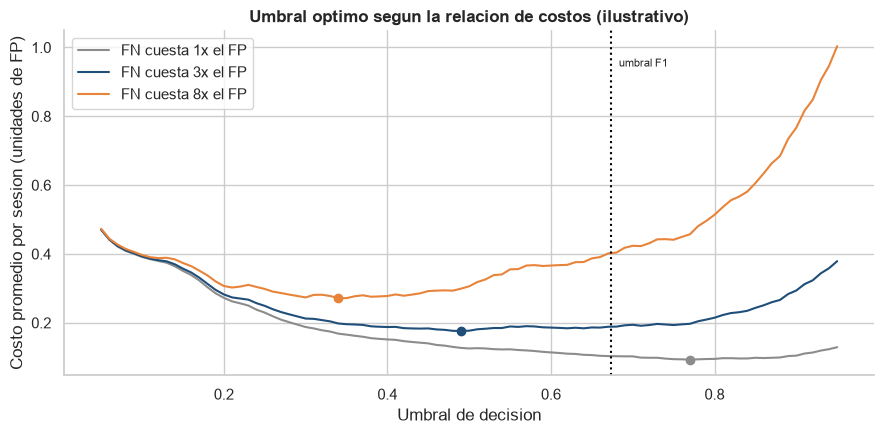

Umbral optimo por relacion de costos: {'FN=1x': np.float64(0.77), 'FN=3x': np.float64(0.49), 'FN=8x': np.float64(0.34)}


In [17]:
prob = probas_test[mejor]
ts = np.linspace(0.05, 0.95, 91)
fig, ax = plt.subplots(figsize=(9, 4.5))
optimos = {}
for k, col in [(1, GRIS), (3, AZUL), (8, NARANJA)]:
    costo = []
    for t in ts:
        p = (prob >= t).astype(int)
        fp = ((p == 1) & (y_test.values == 0)).sum(); fn = ((p == 0) & (y_test.values == 1)).sum()
        costo.append((fp * 1 + fn * k) / len(y_test))
    ax.plot(ts, costo, color=col, label=f'FN cuesta {k}x el FP')
    optimos[k] = ts[int(np.argmin(costo))]
    ax.plot(optimos[k], min(costo), 'o', color=col)
ax.axvline(umbrales[mejor], ls=':', color='black'); ax.text(umbrales[mejor] + .01, ax.get_ylim()[1] * .9, 'umbral F1', fontsize=8)
ax.set_xlabel('Umbral de decision'); ax.set_ylabel('Costo promedio por sesion (unidades de FP)')
ax.set_title('Umbral optimo segun la relacion de costos (ilustrativo)'); ax.legend()
plt.tight_layout()
plt.savefig(FIG / '03_costos_umbral.png', dpi=150, bbox_inches='tight')
plt.show()
print('Umbral optimo por relacion de costos:', {f'FN={k}x': round(v, 2) for k, v in optimos.items()})

**Qué umbral usar depende del costo de equivocarse.**
- Si perder una compra y molestar a un cliente costaran lo mismo (FN = 1×FP), el umbral óptimo sería **alto (0,77)**: solo se intervendría cuando se está muy seguro.
- Si perder una compra cuesta **3 veces** más, el umbral óptimo baja a **0,49**; si cuesta **8 veces** más, a **0,34**: se marcarían muchas más sesiones, a cambio de tolerar más falsas alarmas.
- El umbral de F1 (0,673) está en un punto intermedio que **asume que ambos errores pesan parecido**.
- **En un sistema real de comercio electrónico** el falso positivo es barato (un cupón o un mensaje de ayuda) y el falso negativo es costoso (una venta perdida), por lo que conviene un **umbral más bajo que el de F1**. Los costos reales hay que estimarlos con el negocio (margen del producto, costo del descuento); aquí son **supuestos ilustrativos**.